# Fase 0 · Etapa 0.6 — Elemento de viga, propriedades e dimensões (I3, I4, I14, C8)

> **Bases de dados usadas — leia antes:**
> * **Dados do pesquisador:** CSVs livre-livre da 2ª campanha (`AÇO/`, `Al/`, `ACRILICO/`,
>   16 ensaios cada) — só para identificar as frequências medidas.
> * **Documento do pesquisador:** Tabela 1 do TCC (dimensões dos corpos de prova).
> * **Fabricante (externo):** massa do acelerômetro PCB 352C33 = 5,8 g (datasheet rev. H).
> * **Faixa de PMMA:** E ≈ 2,4–3,3 GPa e ρ ≈ 1180–1200 kg/m³, como registrada no prompt
>   master — `TODO: confirmar com datasheet do fabricante do acrílico ou literatura`.
> * **Soluções analíticas** de Euler–Bernoulli (Blevins) e torção de Saint-Venant
>   (Timoshenko & Goodier). Nenhuma base experimental externa.

**Perguntas.** (1) O elemento e as propriedades do legado estão certos? (2) As
frequências do modelo batem com as medidas? Se não, a diferença é explicável?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg as sla
from scipy.signal import find_peaks

from dampid.analytic import beam
from dampid.audit import legacy_harness as lh
from dampid.audit import reference as ref

B = lh.load_legacy()
MATS = {"aluminio": "Al", "aco": "AÇO", "acrilico": "ACRILICO"}

## 1. I14 — dimensões do código × Tabela 1 do TCC
A Tabela 1 dá `a` (comprimento), `c` (largura) e `f` (espessura); `b`, `d`, `e` são cotas
de posição do desenho do Apêndice A (não legíveis no texto extraído do PDF).

In [2]:
tab1 = {"aco": (314.0, 51.0, 2.90), "aluminio": (304.0, 50.8, 3.20), "acrilico": (301.0, 49.4, 3.00)}
rows = []
for mat, (La, c, f) in tab1.items():
    E, nu, rho, L, a, b, *_ = B.material_prop(mat)
    rows.append({"material": mat, "L código [mm]": 1e3 * L, "L Tab.1": La, "largura código": round(1e3 * a, 2),
                 "largura Tab.1": c, "espessura código": round(1e3 * b, 2), "espessura Tab.1": f,
                 "Δespessura %": round(100 * (1e3 * b / f - 1), 1)})
print(pd.DataFrame(rows).to_string(index=False))

material  L código [mm]  L Tab.1  largura código  largura Tab.1  espessura código  espessura Tab.1  Δespessura %
     aco          285.0    314.0           51.25           51.0              3.04              2.9           4.8
aluminio          271.0    304.0           50.95           50.8              3.16              3.2          -1.2
acrilico          300.0    301.0           49.00           49.4              3.00              3.0           0.0


**Confirmado (I14).** Comprimentos diferem em 29–33 mm nos metais (provavelmente o código
usa o **comprimento livre** do engaste da 1ª campanha e a Tabela 1 o comprimento total
— `TODO: confirmar com o pesquisador`). A espessura do **aço** difere 4,8 %; como a
frequência de flexão é proporcional à espessura, isso sozinho muda f em ~5 %. Nenhuma
das duas fontes registra **medições** (vários pontos com paquímetro/micrômetro).

## 2. I3 — constante de torção

In [3]:
rows = []
for mat in MATS:
    E, nu, rho, L, a, b, Iy, Iz, A, G, J = B.material_prop(mat)
    Jt = beam.torsion_constant_rectangle(a, b)
    f_leg = beam.torsion_frequencies_hz(G, J, rho, Iy + Iz, L, "free-free", 1)[0]
    f_sv = beam.torsion_frequencies_hz(G, Jt, rho, Iy + Iz, L, "free-free", 1)[0]
    rows.append({"material": mat, "J legado = Iy+Iz [m⁴]": f"{J:.3e}", "J_t Saint-Venant [m⁴]": f"{Jt:.3e}",
                 "J/J_t": round(J / Jt, 1), "1ª torção livre-livre legado [Hz]": round(f_leg),
                 "com J_t [Hz]": round(f_sv)})
print(pd.DataFrame(rows).to_string(index=False))

material J legado = Iy+Iz [m⁴] J_t Saint-Venant [m⁴]  J/J_t  1ª torção livre-livre legado [Hz]  com J_t [Hz]
aluminio             3.496e-08             5.150e-10   67.9                               5790           703
     aco             3.422e-08             4.620e-10   74.1                               5495           639
acrilico             2.952e-08             4.240e-10   69.6                               3333           399


**Confirmado (I3).** O legado usa o momento polar `Iy + Iz` como constante de torção. Para
uma seção 50 × 3 mm, o momento polar é ~70 vezes a constante de Saint-Venant: a rigidez
torcional fica ~70× maior e as frequências de torção ~8× maiores. Com J_t correto, a 1ª
torção livre-livre cai de 3–6 kHz para ≈ 640–700 Hz nos metais (logo acima da banda de
0–500 Hz, com pé de pico dentro dela) e ≈ 400 Hz no acrílico (**dentro** da banda).
Impactos fora da linha média excitam torção, então o modelo precisa tê-la na posição
certa — e o 2º acelerômetro a 90° (fibra de vidro, longarina) só faz sentido com isso. (Para a inércia de massa da torção, o momento polar `ρ(Iy+Iz)` está
**certo**; o erro é só na rigidez.)

## 3. I4 — termo de "inércia rotacional"
O legado soma `ρ·Iz·∫Nv Nvᵀ` à massa (deveria ser `ρ·Iz·∫Nv′ Nv′ᵀ`, termo de Rayleigh).
Comparação dos modos de flexão fora do plano, em balanço, malha fina (21 nós):

In [4]:
def w_freqs(rotary, mat="aluminio", n=21):
    K, M = lh.assemble_legacy(B, mat, n, rotary=rotary)
    _, free, _, _ = B.contorno("engastado_livre", 6, n)
    w2, V = sla.eigh(K[np.ix_(free, free)], M[np.ix_(free, free)])
    t = np.array(free) % 6
    share = np.sum(V[(t == 3) | (t == 4)] ** 2, 0) / np.sum(V**2, 0)
    return np.sqrt(w2[share > 0.9])[:4] / 2 / np.pi

fl, fc, fn = w_freqs("legacy"), w_freqs("correct"), w_freqs("none")
print("modo | legado [Hz] | correto [Hz] | sem termo [Hz] | legado vs correto [%]")
for i in range(4):
    print(f"  {i + 1}  | {fl[i]:10.3f} | {fc[i]:11.3f} | {fn[i]:13.3f} | {100 * (fl[i] / fc[i] - 1):+.4f}")

modo | legado [Hz] | correto [Hz] | sem termo [Hz] | legado vs correto [%]
  1  |     35.577 |      35.576 |        35.577 | +0.0026
  2  |    222.960 |     222.919 |       222.960 | +0.0183
  3  |    624.302 |     624.029 |       624.303 | +0.0437
  4  |   1223.440 |    1222.451 |      1223.440 | +0.0809


**Confirmado (I4), efeito numérico desprezível.** O termo está errado (forma e unidades:
ρ·I·∫NNᵀ tem unidade kg·m, somado a ρA·∫NNᵀ em kg/m), mas a diferença nas frequências é
de 0,003 % a 0,08 % nos quatro primeiros modos (≤ 0,02 % nos que caem na banda) para
barras de 3 mm. Corrige-se na Fase 4 sem impacto prático.

## 4. C8 e frequências medidas
### 4.1 Frequências medidas (2ª campanha, livre-livre)
Estimativa simples para auditoria (não é o pipeline da Fase 2): H1 = G_fa/G_ff com os 16
ensaios de cada material, registros de 2,4 s alinhados pelo início da força (5 ms de
pré-trigger), janela retangular, acelerômetro 1 convertido de g para m/s².

aco       picos [Hz]: [157.5 439.6]  coerência nos picos: [0.97 0.67]
aluminio  picos [Hz]: [151.7]  coerência nos picos: [0.91]
acrilico  picos [Hz]: [ 42.1  50.8 304.6]  coerência nos picos: [0.98 0.96 0.98]


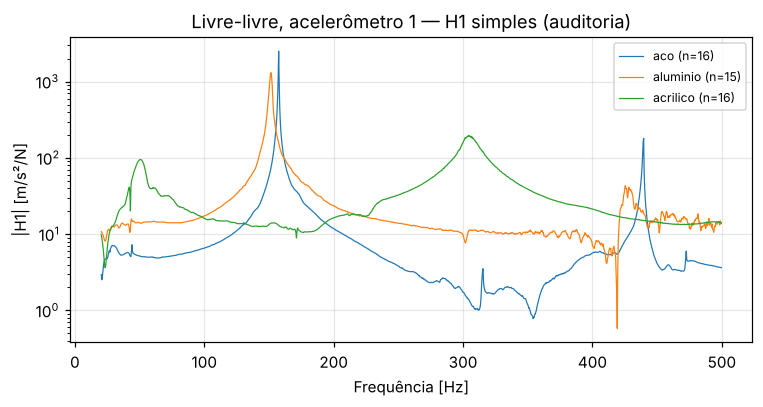

In [5]:
def measured_frf(folder, pattern, sensor=0, T=2.4):
    F, X = [], []
    for i in range(1, 17):
        d = ref.read_ni_csv(lh.RAW_DIR / folder / pattern.format(i))
        fs = d["fs"]
        i0 = ref.force_onset(d["ch"][2], fs) - int(0.005 * fs)
        n = int(T * fs)
        if i0 + n <= d["ch"].shape[1]:
            F.append(d["ch"][2][i0:i0 + n])
            X.append(d["ch"][sensor][i0:i0 + n] * ref.G0)
    f, H, coh = ref.simple_h1(np.array(F), np.array(X), fs)
    return f, H, coh, len(F)

patterns = {"aco": ("AÇO", "LL_ACO_{:02d}.csv"), "aluminio": ("Al", "Al_livre_livre_{}.csv"),
            "acrilico": ("ACRILICO", "LL_ACRILICO_{:02d}.csv")}
meas = {}
fig, ax = plt.subplots(figsize=(8, 3.6))
for mat, (folder, pat) in patterns.items():
    f, H, coh, n = measured_frf(folder, pat)
    sel = (f > 20) & (f < 500)
    p, _ = find_peaks(np.abs(H[sel]), prominence=0.05 * np.abs(H[sel]).max())
    meas[mat] = dict(f=f, H=H, coh=coh, peaks=f[sel][p], n=n)
    ax.semilogy(f[sel], np.abs(H[sel]), lw=0.8, label=f"{mat} (n={n})")
    print(f"{mat:<9} picos [Hz]: {np.round(f[sel][p], 1)}  coerência nos picos: {np.round(coh[sel][p], 2)}")
ax.set(xlabel="Frequência [Hz]", ylabel="|H1| [m/s²/N]", title="Livre-livre, acelerômetro 1 — H1 simples (auditoria)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

No aço, os picos de 157,5 e 439,6 Hz estão na razão 2,79 — muito perto da razão teórica
f₂/f₁ = (7,853/4,730)² = 2,757 dos dois primeiros modos de flexão livre-livre. No
alumínio só o 1º modo (151,7 Hz) aparece com coerência alta. No acrílico há picos em 42,
51 e 305 Hz — a identificação de modos fica para a Fase 3.

### 4.2 Previsões de Euler–Bernoulli (livre-livre, sem sensores)

In [6]:
pmma = {"E": (2.4e9, 3.3e9), "rho": (1180.0, 1200.0)}   # faixa do prompt master (TODO: verificar)
rows = []
for mat, (La, c, t) in tab1.items():
    E, nu, rho, L, a, b, Iy, Iz, A, G, J = B.material_prop(mat)
    f_code = beam.bending_frequencies_hz(E, Iy, rho, A, L, "free-free", 2)
    I1, A1 = c * 1e-3 * (t * 1e-3) ** 3 / 12, c * 1e-3 * t * 1e-3
    f_tab = beam.bending_frequencies_hz(E, I1, rho, A1, La * 1e-3, "free-free", 2)
    row = {"material": mat, "medido f1 [Hz]": round(meas[mat]["peaks"][0] if mat != "acrilico" else np.nan, 1),
           "EB código (dims+props) f1": round(f_code[0], 1), "EB Tab.1 dims + props código f1": round(f_tab[0], 1)}
    if mat == "acrilico":
        lo = beam.bending_frequencies_hz(pmma["E"][0], I1, pmma["rho"][1], A1, La * 1e-3, "free-free", 1)[0]
        hi = beam.bending_frequencies_hz(pmma["E"][1], I1, pmma["rho"][0], A1, La * 1e-3, "free-free", 1)[0]
        row["EB Tab.1 + PMMA típico f1"] = f"{lo:.0f}–{hi:.0f}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print("\nAcrílico: picos medidos em", np.round(meas["acrilico"]["peaks"], 1), "Hz")

material  medido f1 [Hz]  EB código (dims+props) f1  EB Tab.1 dims + props código f1 EB Tab.1 + PMMA típico f1
     aco           157.5                      194.3                            152.7                       NaN
aluminio           151.7                      226.4                            182.2                       NaN
acrilico             NaN                      108.4                            107.6                     48–57

Acrílico: picos medidos em [ 42.1  50.8 304.6] Hz


**Confirmado (C8).** Com E = 20 GPa e ρ = 2000 kg/m³ o legado prevê f₁ ≈ 108 Hz para o
acrílico livre-livre — não há nenhum pico medido perto disso. Com propriedades típicas
de PMMA (faixa a confirmar), f₁ ≈ 48–57 Hz, na ordem dos picos medidos (42/51 Hz). O
E = 20 GPa é ~7× o de um PMMA e não corresponde a nenhum acrílico comercial conhecido.

**Metais.** Sem sensores, o modelo dá f₁(Al) ≈ 182 Hz (dimensões da Tabela 1) contra
151,7 Hz medidos (−17 %), e f₁(aço) ≈ 153 Hz contra 157,5 Hz medidos (+3 %). As duas
discrepâncias têm sinais **opostos**, então não podem ter uma única causa.

### 4.3 Efeito da massa dos conjuntos de sensor
Cada conjunto é: acelerômetro (5,8 g, datasheet) + base roscada de PLA + cera + trecho de
cabo — a massa total por conjunto é desconhecida (≥ 5,8 g). As posições exatas também
(estão no Apêndice A do TCC, cujas figuras não vieram no texto do PDF). Abaixo, a
sensibilidade de f₁ à massa de **dois** conjuntos, nos dois limites de posição: nas
pontas (efeito máximo no 1º modo) e no centro.

aluminio: f1 sem sensores = 182.2 Hz; medido = 151.7 Hz; dois conjuntos nas pontas explicariam com ≈ 7.5 g cada
aco: f1 sem sensores = 152.7 Hz; medido = 157.5 Hz; massa adicionada NÃO explica (o medido é MAIOR que o previsto sem sensores)


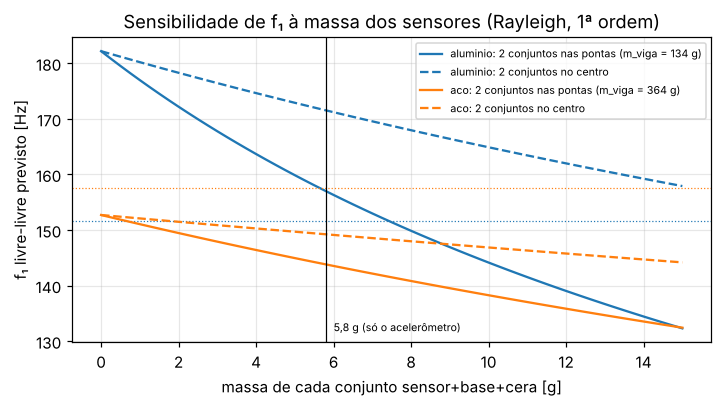

In [7]:
m_asm = np.linspace(0, 15e-3, 61)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for mat, color in [("aluminio", "tab:blue"), ("aco", "tab:orange")]:
    La, c, t = tab1[mat]
    E, nu, rho, *_ = B.material_prop(mat)
    m_beam = rho * La * c * t * 1e-9
    I1, A1 = c * 1e-3 * (t * 1e-3) ** 3 / 12, c * 1e-3 * t * 1e-3
    f0 = beam.bending_frequencies_hz(E, I1, rho, A1, La * 1e-3, "free-free", 1)[0]
    ends = [f0 * beam.point_mass_frequency_factor([0.0, 1.0], [m, m], m_beam, "free-free") for m in m_asm]
    mid = [f0 * beam.point_mass_frequency_factor([0.5, 0.5], [m, m], m_beam, "free-free") for m in m_asm]
    ax.plot(1e3 * m_asm, ends, color=color, label=f"{mat}: 2 conjuntos nas pontas (m_viga = {1e3 * m_beam:.0f} g)")
    ax.plot(1e3 * m_asm, mid, color=color, ls="--", label=f"{mat}: 2 conjuntos no centro")
    ax.axhline(meas[mat]["peaks"][0], color=color, lw=0.8, ls=":")
    fm = meas[mat]["peaks"][0]
    m_needed = [m for m, fe in zip(m_asm, ends) if fe <= fm]
    if f0 < fm:
        msg = "massa adicionada NÃO explica (o medido é MAIOR que o previsto sem sensores)"
    else:
        msg = f"dois conjuntos nas pontas explicariam com ≈ {1e3 * m_needed[0]:.1f} g cada"
    print(f"{mat}: f1 sem sensores = {f0:.1f} Hz; medido = {fm:.1f} Hz; {msg}")
ax.axvline(5.8, color="k", lw=0.8)
ax.text(6.0, ax.get_ylim()[0] + 2, "5,8 g (só o acelerômetro)", fontsize=7)
ax.set(xlabel="massa de cada conjunto sensor+base+cera [g]", ylabel="f₁ livre-livre previsto [Hz]",
       title="Sensibilidade de f₁ à massa dos sensores (Rayleigh, 1ª ordem)")
ax.grid(alpha=0.3); ax.legend(fontsize=7)

**Leitura (hipóteses, não conclusões).**
* **Alumínio:** dois conjuntos de ≈ 7–8 g perto das pontas explicariam os 151,7 Hz —
  compatível com 5,8 g do acelerômetro + ~2 g de base de PLA, cera e cabo. É a explicação
  mais simples para o achado 5 da §2.3, mas depende das posições reais.
* **Aço:** o medido (157,5 Hz) já é **maior** que o previsto sem sensores (153 Hz com a
  espessura de 2,90 mm da Tabela 1). Massa adicionada só piora. Com a espessura do código
  (3,04 mm) a previsão sobe ~5 %. Ou seja, a espessura do aço (ou o seu E) precisa ser
  **medida**: a diferença entre as duas fontes de dimensões é maior que o efeito que
  queremos modelar.

Isso reforça C7/H2: antes de qualquer identificação de amortecimento é preciso fechar
massa e rigidez (Fase 5), e para isso as dimensões, posições e massas dos conjuntos
sensor+base são necessárias.

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| I14 | **confirmado** | L difere 29–33 mm (metais); espessura do aço difere 4,8 % entre código e TCC |
| I3 | **confirmado** | J = Iy+Iz ≈ 70 × J_t; 1ª torção ~8× alta (legado 3–6 kHz; correto ≈ 400–700 Hz) |
| I4 | **confirmado, efeito desprezível** | termo errado, Δf ≤ 0,08 % |
| C8 | **confirmado** | acrílico legado f₁ ≈ 108 Hz, sem pico medido perto; PMMA típico → 48–57 Hz |
| (novo) N3 | **aberto** | Al: −17 % explicável por ~7–8 g por conjunto; aço: +3 % **não** explicável por massa → dimensões/E do aço precisam ser medidos |